# Academic Success Prediction

## 1. Project Overview

This project uses machine learning to predict students' academic outcomes based on demographic, socioeconomic, and academic-related factors.

## 2. Project Objectives

- Explore factors associated with students' academic outcomes.
- Perform data preprocessing and exploratory data analysis.
- Develop and evaluate classification models.
- Compare model performance to identify the most suitable approach.

In [1]:
import pandas as pd

dataset = pd.read_csv("data.csv", sep=";")

print("Dataset shape:", dataset.shape)
display(dataset.head())

Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 3. Initial Data Inspection

In [2]:
# Dataset information
dataset.info()

# Statistical summary
display(dataset.describe())

# Missing values
print("\nMissing values per column:")
print(dataset.isnull().sum())

# Duplicate records
print("\nDuplicate records:", dataset.duplicated().sum())

# Target distribution
print("\nTarget distribution:")
print(dataset["Target"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000



Missing values per column:
Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                  

In [3]:
print("Target distribution:")
print(dataset["Target"].value_counts())

print("\nTarget distribution (%):")
print(dataset["Target"].value_counts(normalize=True).mul(100).round(2))

Target distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Target distribution (%):
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


## 4. Data Cleaning
Check and remove duplicate records to ensure data quality.

In [4]:
# Remove duplicate records
dataset = dataset.drop_duplicates()

print("Dataset shape after removing duplicates:", dataset.shape)
print("Remaining duplicates:", dataset.duplicated().sum())

Dataset shape after removing duplicates: (4424, 37)
Remaining duplicates: 0


## 5. Exploratory Data Analysis

### 5.1 Distribution of Academic Outcomes

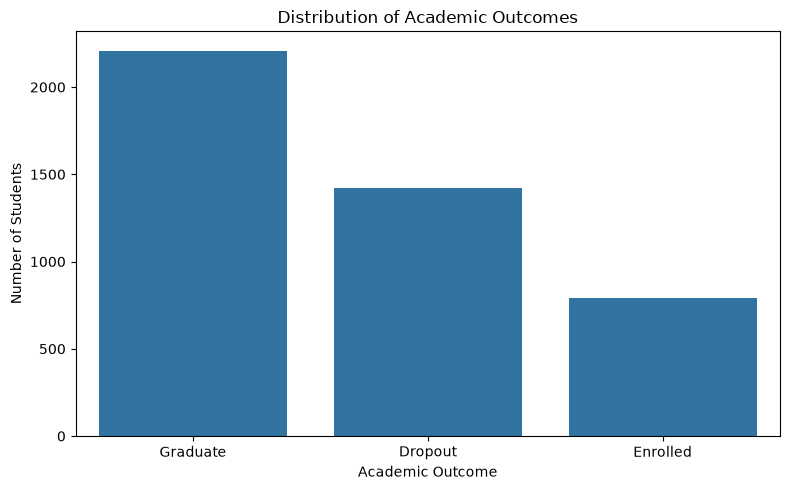

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=dataset,
    x="Target",
    order=dataset["Target"].value_counts().index
)

plt.title("Distribution of Academic Outcomes")
plt.xlabel("Academic Outcome")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

### 5.2 Academic Outcomes by Gender

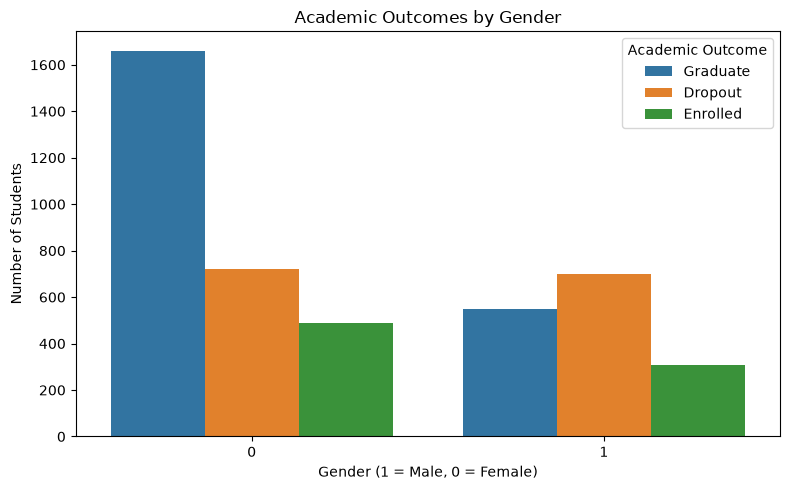

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=dataset,
    x="Gender",
    hue="Target"
)

plt.title("Academic Outcomes by Gender")
plt.xlabel("Gender (1 = Male, 0 = Female)")
plt.ylabel("Number of Students")
plt.legend(title="Academic Outcome")
plt.tight_layout()
plt.show()

### 5.3 First-Semester Performance by Academic Outcome

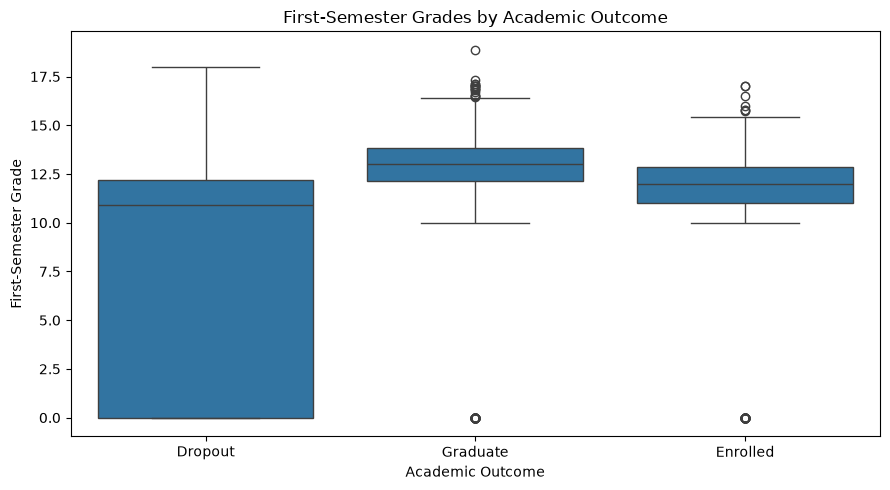

In [7]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=dataset,
    x="Target",
    y="Curricular units 1st sem (grade)"
)

plt.title("First-Semester Grades by Academic Outcome")
plt.xlabel("Academic Outcome")
plt.ylabel("First-Semester Grade")
plt.tight_layout()
plt.show()

## 6. Data Preprocessing

### 6.1 Feature and Target Separation

In [8]:
# Separate input features and target variable
X = dataset.drop(columns=["Target"])
y = dataset["Target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4424, 36)
Target shape: (4424,)


### 6.2 Feature Type Identification

In [9]:
# Define numerical and categorical features
categorical_features = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance\t",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

numerical_features = [
    column for column in X.columns
    if column not in categorical_features
]

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Categorical features: 17
Numerical features: 19


### 6.3 Train-Test Split

Split the dataset into training and testing sets while preserving the original target-class distribution.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

Training features: (3539, 36)
Testing features: (885, 36)

Training target distribution:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


### 6.4 Feature Preprocessing

Scale numerical features and one-hot encode categorical features using a preprocessing pipeline.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Preprocess numerical features
numerical_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


### 6.5 Apply Preprocessing

In [12]:
# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (3539, 244)
Processed testing shape: (885, 244)


## 7. Model Training – Logistic Regression

In this section, we train a Logistic Regression model to predict whether a student is likely to Dropout, Graduate, or remain Enrolled.

Logistic Regression is used as our baseline classification model. It helps us establish an initial performance benchmark before comparing it with other machine learning algorithms.

In [13]:
from sklearn.linear_model import LogisticRegression

# Initialize the model
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
log_reg.fit(X_train_processed, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


## 8. Model Evaluation – Logistic Regression

Evaluate the model on the test dataset using accuracy, precision, recall, F1-score, and a confusion matrix.

Logistic Regression Accuracy: 77.06 %

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.79      0.76      0.77       284
    Enrolled       0.56      0.39      0.46       159
    Graduate       0.81      0.91      0.86       442

    accuracy                           0.77       885
   macro avg       0.72      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885



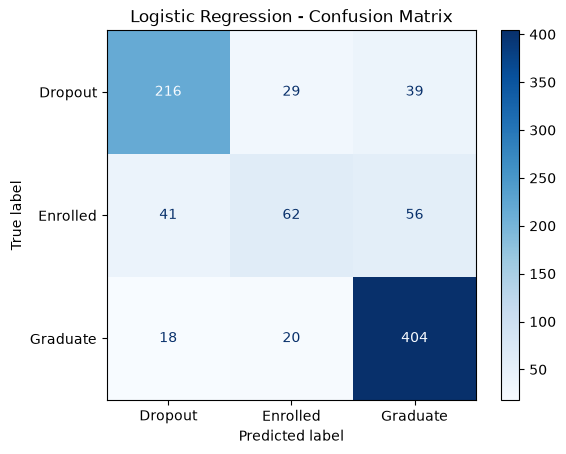

In [14]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Make predictions
y_pred = log_reg.predict(X_test_processed)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=log_reg.classes_
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

## 9. Model Training – Random Forest

Train a Random Forest classifier to capture more complex relationships in the student dataset.

In [15]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


## 10. Model Evaluation – Random Forest

Evaluate the Random Forest model on the test dataset and examine its classification performance.

Random Forest Accuracy: 76.61 %

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.79      0.78      0.79       284
    Enrolled       0.61      0.29      0.39       159
    Graduate       0.78      0.93      0.85       442

    accuracy                           0.77       885
   macro avg       0.72      0.67      0.67       885
weighted avg       0.75      0.77      0.74       885



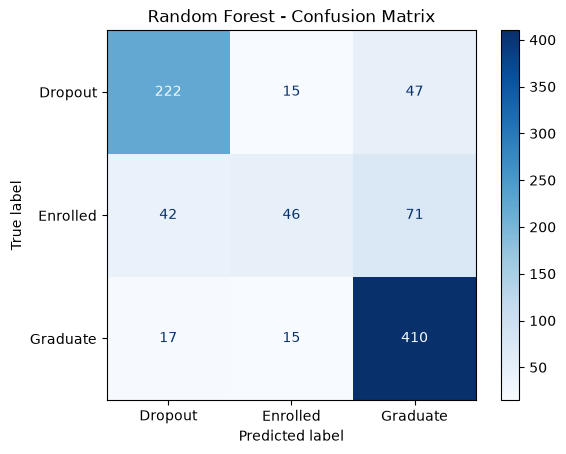

In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Make predictions
y_pred_rf = rf_model.predict(X_test_processed)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=rf_model.classes_
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

## 11. Model Training – XGBoost

In [19]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Encode target labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Initialize the model
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_processed, y_train_encoded)

print("XGBoost training completed!")

XGBoost training completed!


## 12. Model Evaluation – XGBoost

Evaluate XGBoost on the test dataset using accuracy, precision, recall, F1-score, and a confusion matrix.

XGBoost Accuracy: 76.05 %

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.80      0.72      0.76       284
    Enrolled       0.51      0.41      0.45       159
    Graduate       0.80      0.91      0.85       442

    accuracy                           0.76       885
   macro avg       0.70      0.68      0.69       885
weighted avg       0.75      0.76      0.75       885



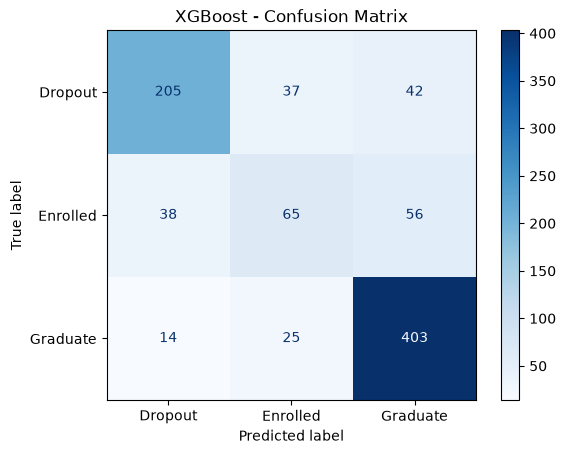

In [20]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Make predictions
y_pred_xgb_encoded = xgb_model.predict(X_test_processed)

# Convert predictions back to original class labels
y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_encoded)

# Calculate accuracy
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", round(xgb_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

# Confusion matrix
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=label_encoder.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues")
plt.title("XGBoost - Confusion Matrix")
plt.show()

## 13. Feature Importance

Analyze feature importance from the Random Forest model to identify the features that contribute most to predicting student outcomes.

                                         Feature  Importance
13      num__Curricular units 2nd sem (approved)    0.106954
14         num__Curricular units 2nd sem (grade)    0.085964
7       num__Curricular units 1st sem (approved)    0.072277
8          num__Curricular units 1st sem (grade)    0.060756
12   num__Curricular units 2nd sem (evaluations)    0.036953
2                           num__Admission grade    0.033925
3                         num__Age at enrollment    0.031206
6    num__Curricular units 1st sem (evaluations)    0.031035
1            num__Previous qualification (grade)    0.029688
237               cat__Tuition fees up to date_1    0.028686
236               cat__Tuition fees up to date_0    0.021782
16                        num__Unemployment rate    0.020722
18                                      num__GDP    0.020521
11      num__Curricular units 2nd sem (enrolled)    0.018592
17                           num__Inflation rate    0.018260


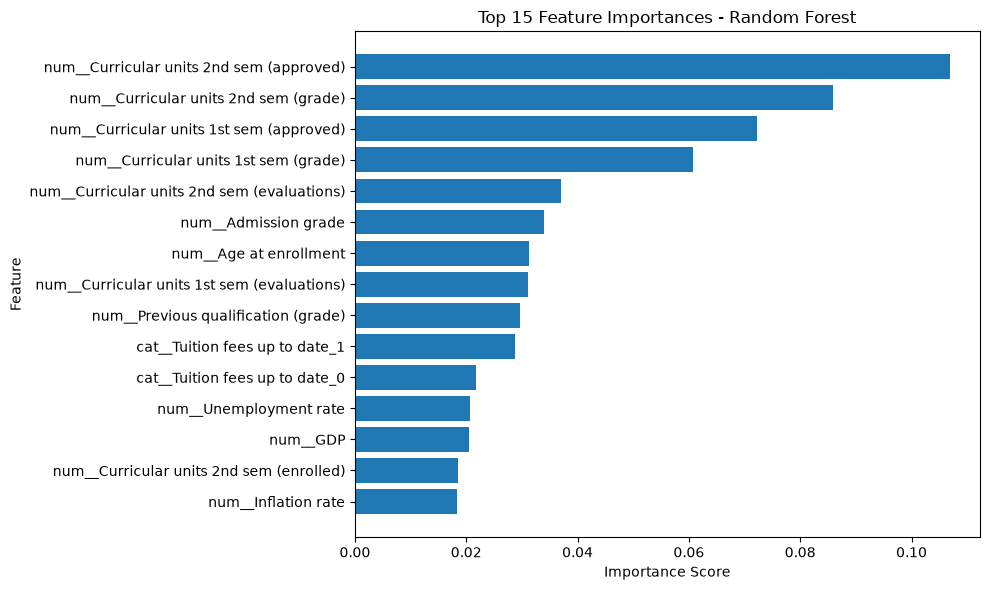

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance scores
feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
top_features = feature_importance.head(15)

print(top_features)

# Visualize feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Random Forest")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 14. Model Training – MLP Classifier

Train a Multi-Layer Perceptron (MLP) classifier to evaluate a neural network approach for student outcome prediction.

In [24]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Initialize the model
mlp_model = make_pipeline(
    StandardScaler(with_mean=False),
    MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        max_iter=300,
        early_stopping=True,
        random_state=42
    )
)

# Train the model
mlp_model.fit(X_train_processed, y_train)

print("MLP training completed!")

MLP training completed!


## 15. Model Evaluation – MLP Classifier

Evaluate the MLP model using accuracy, precision, recall, F1-score, and a confusion matrix.

MLP Accuracy: 72.2 %

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.80      0.72      0.76       284
    Enrolled       0.40      0.29      0.33       159
    Graduate       0.76      0.88      0.81       442

    accuracy                           0.72       885
   macro avg       0.65      0.63      0.64       885
weighted avg       0.71      0.72      0.71       885



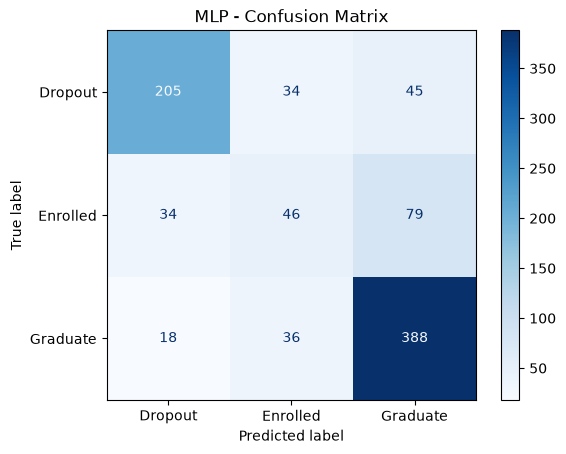

In [25]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Make predictions
y_pred_mlp = mlp_model.predict(X_test_processed)

# Calculate accuracy
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)

print("MLP Accuracy:", round(mlp_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_mlp))

# Confusion matrix
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=mlp_model.classes_
)

disp.plot(cmap="Blues")
plt.title("MLP - Confusion Matrix")
plt.show()

## 16. Model Performance Comparison

Compare all four classifiers using accuracy, weighted precision, weighted recall, weighted F1-score, and macro F1-score.

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Logistic Regression": y_pred,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "MLP": y_pred_mlp
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Weighted)": precision_score(
            y_test, predictions, average="weighted"
        ),
        "Recall (Weighted)": recall_score(
            y_test, predictions, average="weighted"
        ),
        "F1 (Weighted)": f1_score(
            y_test, predictions, average="weighted"
        ),
        "F1 (Macro)": f1_score(
            y_test, predictions, average="macro"
        )
    })

comparison_df = pd.DataFrame(results)

comparison_df.round(3)

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1 (Weighted),F1 (Macro)
0,Logistic Regression,0.771,0.757,0.771,0.759,0.697
1,Random Forest,0.766,0.750,0.766,0.745,0.674
2,XGBoost,0.760,0.750,0.760,0.752,0.689
3,MLP,0.722,0.706,0.722,0.710,0.635


### Model Comparison and Selection

Four classification models were evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, and macro F1-score.

Logistic Regression achieved the highest overall accuracy (77.06%) and macro F1-score (0.697) among the evaluated models.

Although it performed well overall, its recall for the Enrolled class was relatively low. This indicated that the model struggled to identify some students who remained enrolled.

Therefore, Logistic Regression was selected as the baseline model for further investigation. A class-weighted version was subsequently tested to examine whether class imbalance could be addressed.

## Class-wise Performance Analysis

We will examine precision, recall, and F1-score for each student outcome category to identify where the model needs improvement.

In [28]:
from sklearn.metrics import classification_report
import pandas as pd

class_performance = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        output_dict=True
    )
).T

class_performance.round(3)

,precision,recall,f1-score,support
Dropout,0.785,0.761,0.773,284.000
Enrolled,0.559,0.390,0.459,159.000
Graduate,0.810,0.914,0.859,442.000
accuracy,0.771,0.771,0.771,0.771
macro avg,0.718,0.688,0.697,885.000
weighted avg,0.757,0.771,0.759,885.000


## Handling Class Imbalance

We will train another Logistic Regression model using balanced class weights to improve its ability to identify underrepresented student outcome categories.

In [29]:
log_reg_balanced = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

log_reg_balanced.fit(X_train_processed, y_train)

y_pred_balanced = log_reg_balanced.predict(X_test_processed)

print("Balanced Logistic Regression Results:")
print(classification_report(y_test, y_pred_balanced))

Balanced Logistic Regression Results:
              precision    recall  f1-score   support

     Dropout       0.82      0.68      0.74       284
    Enrolled       0.42      0.64      0.50       159
    Graduate       0.86      0.79      0.82       442

    accuracy                           0.73       885
   macro avg       0.70      0.70      0.69       885
weighted avg       0.77      0.73      0.74       885



## Balanced Model - Confusion Matrix

We will visualize the balanced Logistic Regression model's predictions to understand how class weighting changed its classification errors.

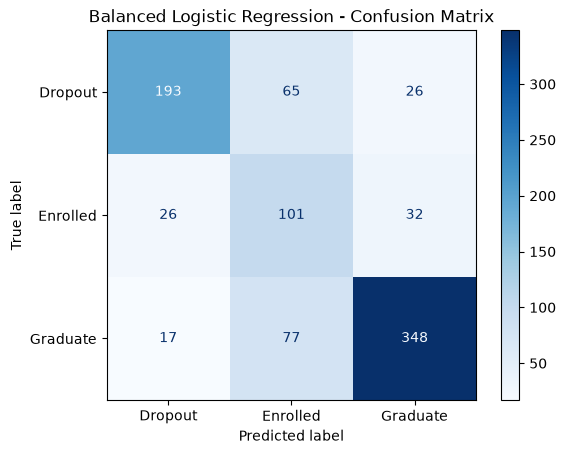

In [30]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=log_reg_balanced.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.show()

## Original vs Balanced Logistic Regression

We will compare both models using accuracy, weighted F1-score, macro F1-score, and class-wise performance to understand the effect of class weighting.

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models_to_compare = {
    "Original Logistic Regression": y_pred,
    "Balanced Logistic Regression": y_pred_balanced
}

comparison_results = []

for model_name, predictions in models_to_compare.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Weighted)": precision_score(
            y_test, predictions, average="weighted"
        ),
        "Recall (Weighted)": recall_score(
            y_test, predictions, average="weighted"
        ),
        "F1 (Weighted)": f1_score(
            y_test, predictions, average="weighted"
        ),
        "F1 (Macro)": f1_score(
            y_test, predictions, average="macro"
        ),
        "Enrolled Recall": recall_score(
            y_test, predictions, labels=["Enrolled"],
            average=None
        )[0]
    })

pd.DataFrame(comparison_results).round(3)

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1 (Weighted),F1 (Macro),Enrolled Recall
0,Original Logistic Regression,0.771,0.757,0.771,0.759,0.697,0.390
1,Balanced Logistic Regression,0.725,0.765,0.725,0.738,0.689,0.635


## Saving Trained Models

We will save both Logistic Regression models and the preprocessing pipeline so they can be reused without retraining.

In [33]:
import joblib

joblib.dump(log_reg, "logistic_regression_model.pkl")
joblib.dump(log_reg_balanced, "balanced_logistic_regression_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

print("Models and preprocessing pipeline saved successfully!")

Models and preprocessing pipeline saved successfully!


## Testing Saved Models

We will load the saved models and preprocessing pipeline to verify that they can be reused for predictions without retraining.

In [34]:
import joblib

loaded_model = joblib.load("logistic_regression_model.pkl")
loaded_preprocessor = joblib.load("preprocessor.pkl")

loaded_predictions = loaded_model.predict(X_test_processed)

print("Saved model loaded successfully!")
print("Predictions:", loaded_predictions[:10])

Saved model loaded successfully!
Predictions: ['Graduate' 'Graduate' 'Dropout' 'Graduate' 'Graduate' 'Dropout'
 'Graduate' 'Graduate' 'Graduate' 'Graduate']


## Prediction Consistency Check

We will compare predictions from the original and loaded models to verify that saving and loading did not change model behavior.

In [35]:
import numpy as np

predictions_match = np.array_equal(y_pred, loaded_predictions)

print("Predictions match:", predictions_match)


Predictions match: True


## Final Findings and Conclusion

### Key Findings

1. Four classification models were evaluated: Logistic Regression, Random Forest, XGBoost, and MLP.
2. Logistic Regression achieved the best overall performance, with 77.06% accuracy.
3. The model performed best at identifying Graduate students, with 91.4% recall.
4. Enrolled students were the most challenging class to predict, with 39.0% recall in the original model.
5. Using balanced class weights improved Enrolled recall to 63.5%, but reduced overall accuracy to 72.5%.
6. Academic performance features, particularly approved curricular units and semester grades, were among the most influential features.

### Conclusion

The experiment demonstrates that machine learning can help predict student academic outcomes using demographic, academic, and socioeconomic information.

Logistic Regression was selected as the primary model based on its overall performance, while Balanced Logistic Regression was retained as an alternative for improved Enrolled-student detection.

Further improvements could explore feature selection, hyperparameter tuning, and strategies for improving minority-class classification.

## Prediction Timing and Feature Availability

This project uses academic, demographic, and socioeconomic features to predict student outcomes.

Some academic features come from the first and second semesters. These may limit how early the model can make reliable predictions.

Future improvements should investigate using only information available at the intended prediction time.